# Cuaderno de Trabajo: Análisis Exploratorio de Datos (EDA)
**Proyecto Integrador - Fase 1**
* **Autor:** William Fernando Latorre Ortiz
* **Asignatura:** Ciencia de Datos
* **Maestría en Inteligencia Artificial** - Universidad de La Salle

In [1]:
# Importar librerías estándar para análisis y visualización
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración de estilo visual para gráficos
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
print("Librerías importadas correctamente.")

Librerías importadas correctamente.


In [7]:
# ==========================================
# Conexión con Google Drive y Carga del Dataset
# ==========================================
from google.colab import drive
import pandas as pd
import numpy as np

# 1. Montar tu Google Drive (te pedirá autorizar el acceso en una ventana emergente)
drive.mount('/content/drive')

# 2. Ruta del archivo en tu Google Drive
# (Por defecto, si está en la carpeta principal de tu Drive, la ruta es esta:)
ruta_archivo = '/content/drive/My Drive/household_power_consumption.csv'

# Si lo tienes dentro de una carpeta específica en tu Drive, cambia la ruta así:
# ruta_archivo = '/content/drive/My Drive/Nombre_De_Tu_Carpeta/household_power_consumption.csv'

# 3. Cargar el dataset (usando coma ',' como separador según tu archivo y manejando los '?' como nulos)
df = pd.read_csv(ruta_archivo, sep=',', low_memory=False, na_values=['?'])

# Limpiar posibles espacios en blanco en los nombres de las columnas
df.columns = df.columns.str.strip()

# Verificación de carga exitosa
print("¡Dataset conectado y cargado con éxito desde Google Drive!")
print(f"Dimensiones del dataset: {df.shape}")
print("Columnas detectadas:", df.columns.tolist())
df.head()

Mounted at /content/drive
¡Dataset conectado y cargado con éxito desde Google Drive!
Dimensiones del dataset: (1048575, 9)
Columnas detectadas: ['Date', 'Time', 'Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


## 1. Diagnóstico de Calidad y Análisis Univariado
En esta sección se evalúa el porcentaje de valores perdidos, duplicados y las principales medidas de tendencia central y dispersión para las variables cuantitativas.

In [8]:
# ==========================================
# DIAGNÓSTICO Y RESUMEN UNIVARIADO SEGURO
# ==========================================

# 1. Asegurar que los nombres de las columnas no tengan espacios ocultos
df.columns = df.columns.str.strip()

# 2. Definir las columnas numéricas clave de forma dinámica
numeric_cols = ['Global_active_power', 'Global_reactive_power', 'Voltage',
                'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']

# Filtrar solo las que existan en el DataFrame para evitar errores
numeric_cols = [col for col in numeric_cols if col in df.columns]

# 3. Diagnóstico de valores faltantes (porcentaje)
missing_data = df[numeric_cols].isnull().mean() * 100
print("Porcentaje de valores faltantes por variable (%):")
print(missing_data)

# 4. Diagnóstico de duplicados
duplicates = df.duplicated().sum()
print(f"\nCantidad de registros duplicados en el dataset: {duplicates}")

# 5. Resumen estadístico descriptivo univariado completo
univariado_stats = df[numeric_cols].describe().T[['mean', 'std', 'min', '50%', 'max']]
univariado_stats.rename(columns={'50%': 'median'}, inplace=True)
univariado_stats['skewness'] = df[numeric_cols].skew() # Asimetría
univariado_stats['kurtosis'] = df[numeric_cols].kurtosis() # Curtosis

print("\n--- Estadísticas Descriptivas Univariadas ---")
display(univariado_stats)

Porcentaje de valores faltantes por variable (%):
Global_active_power      0.38805
Global_reactive_power    0.38805
Voltage                  0.38805
Global_intensity         0.38805
Sub_metering_1           0.38805
Sub_metering_2           0.38805
Sub_metering_3           0.38805
dtype: float64

Cantidad de registros duplicados en el dataset: 0

--- Estadísticas Descriptivas Univariadas ---


,mean,std,min,median,max,skewness,kurtosis
Global_active_power,1.108202,1.129546,0.076,0.550,10.67,1.771386,3.854073
Global_reactive_power,0.118273,0.109506,0.000,0.098,1.39,1.247361,2.537059
Voltage,239.959803,3.284504,223.490,240.210,252.14,-0.352153,0.289279
Global_intensity,4.718123,4.763588,0.200,2.400,46.40,1.828080,4.197417
Sub_metering_1,1.177451,6.321183,0.000,0.000,80.00,5.734676,32.811593
Sub_metering_2,1.475177,6.352703,0.000,0.000,78.00,6.309726,45.230966
Sub_metering_3,5.933837,8.210398,0.000,0.000,31.00,0.766779,-1.301794


## 2. Análisis Bivariado (Matriz de Correlación de Pearson)
Evaluamos la relación lineal entre las variables eléctricas del hogar para identificar dependencias clave de cara a los modelos predictivos de las siguientes fases.

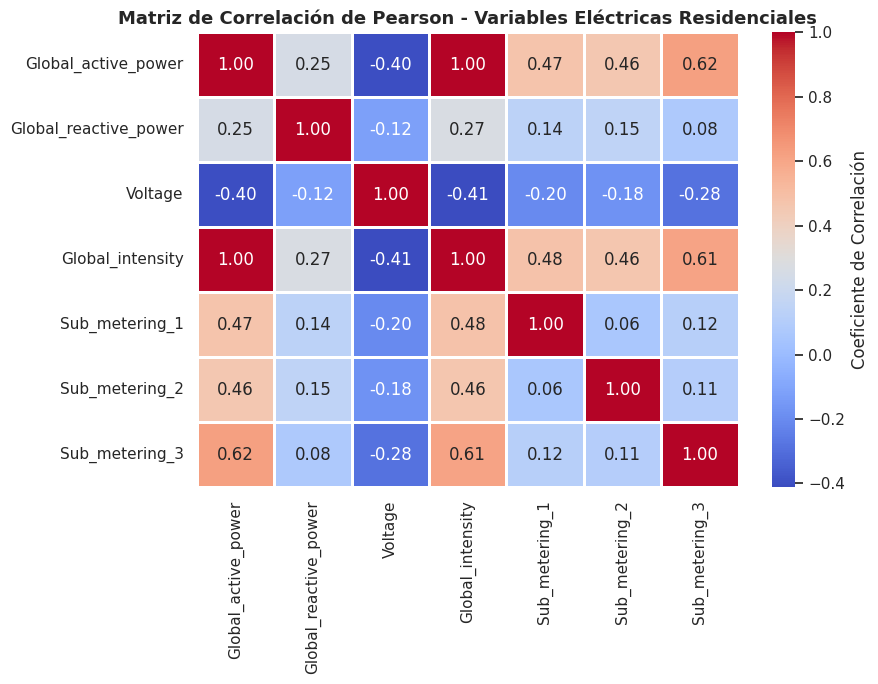

In [9]:
# ==========================================
# ANÁLISIS BIVARIADO: MATRIZ DE CORRELACIÓN
# ==========================================
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual de los gráficos
sns.set_theme(style="whitegrid")

# 1. Asegurar que solo usemos las columnas numéricas existentes
numeric_cols = df.select_dtypes(include=['number']).columns.tolist()

# 2. Calcular la matriz de correlación de Pearson
corr_matrix = df[numeric_cols].corr(method='pearson')

# 3. Generar el mapa de calor (Heatmap)
plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.8, cbar_kws={'label': 'Coeficiente de Correlación'})
plt.title("Matriz de Correlación de Pearson - Variables Eléctricas Residenciales", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()